# SMART DISEASE RISK PREDICTION SYSTEM
## Comprehensive Exploratory Data Analysis & Machine Learning Pipeline
### College ML Project Demonstration & Viva Notebook

**Objective:** Build, benchmark, and evaluate multiple classification algorithms (Logistic Regression, Decision Tree, Random Forest, Support Vector Machine) alongside a Soft Voting Ensemble to estimate patient cardio-metabolic risk from 13 medical biomarkers.

> **Academic Disclaimer:** This notebook and dataset are developed for academic research and college demonstration purposes only. They do not constitute diagnostic medical advice.

### Step 1: Import Core Libraries

In [1]:
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set plotting aesthetics
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 10

# Scikit-Learn tools
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, classification_report
)

print("Libraries successfully imported!")

Libraries successfully imported!


### Step 2: Load Educational Medical Dataset

In [2]:
# Load dataset from data directory
data_path = Path("../data/disease_data.csv")
if not data_path.exists():
    data_path = Path("data/disease_data.csv")

df = pd.read_csv(data_path)
print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")

Dataset Shape: 1500 rows, 14 columns


### Step 3: Inspect Raw Data & First 5 Rows

In [3]:
df.head(10)

,age,gender,blood_pressure,glucose,cholesterol,bmi,heart_rate,smoking,physical_activity,family_history,diabetes,hypertension,heart_disease,target
0,71,Male,143.1,158.6,192.6,22.0,77,Former,High,No,Yes,Yes,Yes,1
1,34,Female,136.4,87.1,218.4,23.7,77,No,Low,No,No,Yes,No,0
2,80,Female,140.1,198.4,185.5,21.0,77,No,High,No,Yes,Yes,No,1
3,40,Male,143.4,101.6,189.3,24.0,62,Yes,High,No,No,Yes,No,0
4,43,Female,124.9,111.6,186.1,28.2,69,No,Low,No,No,Yes,No,0
5,22,Male,110.2,93.3,225.3,25.2,70,Yes,Low,Yes,No,No,No,0
6,41,Female,162.8,90.0,166.9,24.5,91,Yes,Moderate,Yes,Yes,Yes,Yes,1
7,72,Male,124.2,96.9,185.9,25.6,73,No,High,No,No,No,No,0
8,21,Female,121.2,109.1,191.3,25.1,95,No,Low,No,No,No,No,0
9,49,Female,139.3,93.1,179.5,26.3,68,No,Moderate,No,No,Yes,No,0


### Step 4: Check Missing Values & Duplicates

In [4]:
print("=== Missing Values Check ===")
print(df.isnull().sum())

print("\n=== Duplicate Records Check ===")
dup_count = df.duplicated().sum()
print(f"Total Duplicate Rows: {dup_count}")
if dup_count > 0:
    df = df.drop_duplicates().reset_index(drop=True)
    print("Duplicates removed.")

=== Missing Values Check ===
age                  0
gender               0
blood_pressure       0
glucose              0
cholesterol          0
bmi                  0
heart_rate           0
smoking              0
physical_activity    0
family_history       0
diabetes             0
hypertension         0
heart_disease        0
target               0
dtype: int64

=== Duplicate Records Check ===
Total Duplicate Rows: 0


### Step 5: Statistical Summary & Data Types

In [5]:
print("=== Data Types Info ===")
df.info()

print("\n=== Numerical Features Summary Statistics ===")
df.describe().T

=== Data Types Info ===
<class 'pandas.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   age                1500 non-null   int64  
 1   gender             1500 non-null   str    
 2   blood_pressure     1500 non-null   float64
 3   glucose            1500 non-null   float64
 4   cholesterol        1500 non-null   float64
 5   bmi                1500 non-null   float64
 6   heart_rate         1500 non-null   int64  
 7   smoking            1500 non-null   str    
 8   physical_activity  1500 non-null   str    
 9   family_history     1500 non-null   str    
 10  diabetes           1500 non-null   str    
 11  hypertension       1500 non-null   str    
 12  heart_disease      1500 non-null   str    
 13  target             1500 non-null   int64  
dtypes: float64(4), int64(3), str(7)
memory usage: 164.2 KB

=== Numerical Features Summary Statistics ===


,count,mean,std,min,25%,50%,75%,max
age,1500.0,51.944667,19.041691,20.0,36.000,52.00,69.000,84.0
blood_pressure,1500.0,133.428200,16.917511,90.0,120.975,133.45,145.950,184.5
glucose,1500.0,119.986467,35.897421,70.0,92.700,104.15,151.275,230.7
cholesterol,1500.0,195.855400,24.590077,120.0,177.850,195.85,212.400,310.8
bmi,1500.0,26.694133,4.384066,16.5,23.800,26.80,29.600,39.7
heart_rate,1500.0,72.829333,8.376574,50.0,67.000,73.00,78.250,105.0
target,1500.0,0.500000,0.500167,0.0,0.000,0.50,1.000,1.0


### Step 6: Target Distribution Analysis

Target Class Frequencies:
  Class 0 (Low Risk):  750 (50.0%)
  Class 1 (High Risk): 750 (50.0%)


C:\Users\chsas\AppData\Local\Temp\ipykernel_16540\3507110292.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="target", palette=["#10b981", "#ef4444"])


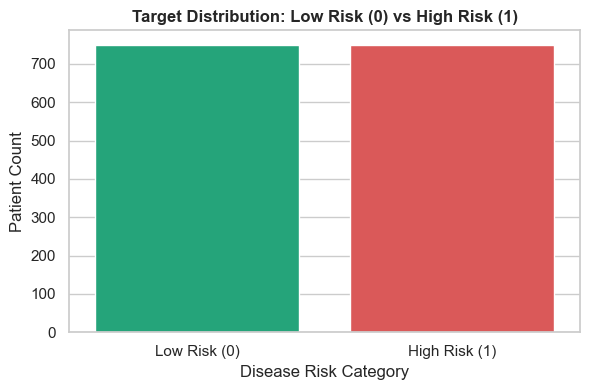

In [6]:
target_counts = df["target"].value_counts()
print("Target Class Frequencies:")
print(f"  Class 0 (Low Risk):  {target_counts[0]} ({target_counts[0]/len(df)*100:.1f}%)")
print(f"  Class 1 (High Risk): {target_counts[1]} ({target_counts[1]/len(df)*100:.1f}%)")

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="target", palette=["#10b981", "#ef4444"])
plt.title("Target Distribution: Low Risk (0) vs High Risk (1)", weight="bold")
plt.xticks([0, 1], ["Low Risk (0)", "High Risk (1)"])
plt.xlabel("Disease Risk Category")
plt.ylabel("Patient Count")
plt.tight_layout()
plt.show()

### Step 7: Physiological Feature Distributions

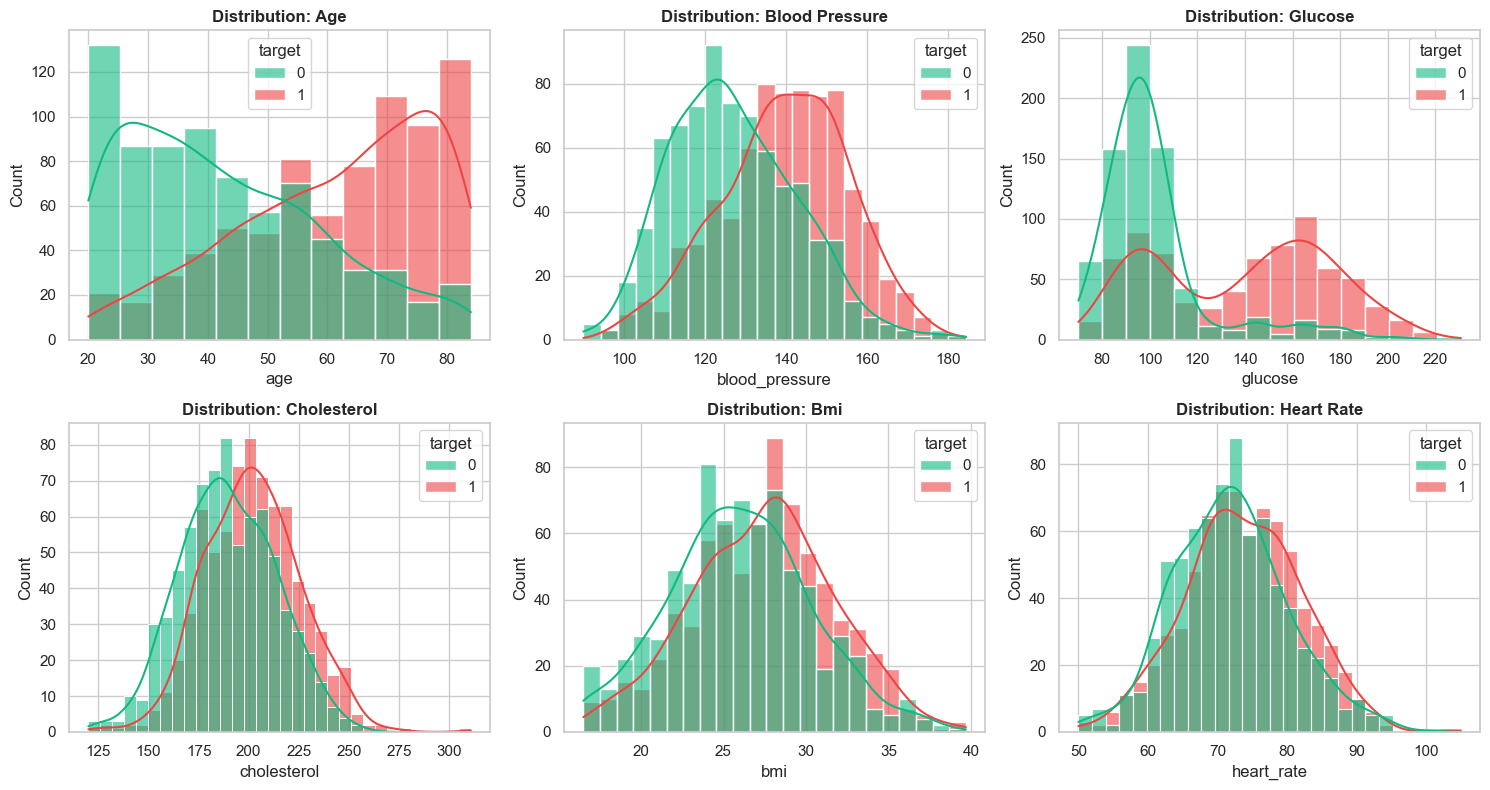

In [7]:
num_features = ["age", "blood_pressure", "glucose", "cholesterol", "bmi", "heart_rate"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for i, col in enumerate(num_features):
    ax = axes[i // 3, i % 3]
    sns.histplot(data=df, x=col, hue="target", kde=True, ax=ax, palette=["#10b981", "#ef4444"], alpha=0.6)
    ax.set_title(f"Distribution: {col.replace('_', ' ').title()}", weight="bold")
plt.tight_layout()
plt.show()

### Step 8: Correlation Matrix Heatmap

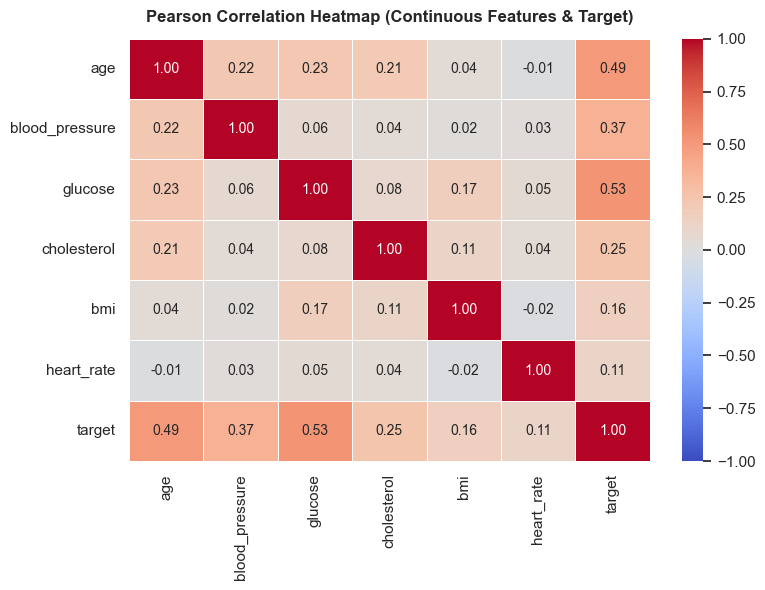

In [8]:
# Compute Pearson correlation for numerical variables
corr = df[num_features + ["target"]].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.5)
plt.title("Pearson Correlation Heatmap (Continuous Features & Target)", weight="bold", pad=12)
plt.tight_layout()
plt.show()

### Step 9: Train / Test Split & Preprocessing Pipeline

In [9]:
cat_features = [
    "gender", "smoking", "physical_activity", "family_history",
    "diabetes", "hypertension", "heart_disease"
]

X = df[num_features + cat_features]
y = df["target"]

# 80% Train, 20% Test (Stratified)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print(f"X_train: {X_train.shape}, X_test: {X_test.shape}")

# Preprocessor construction
num_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

cat_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer([
    ("num", num_transformer, num_features),
    ("cat", cat_transformer, cat_features)
])

# Strictly fit on training set only
X_train_trans = preprocessor.fit_transform(X_train)
X_test_trans = preprocessor.transform(X_test)
print(f"Transformed Training Matrix Shape: {X_train_trans.shape}")

X_train: (1200, 13), X_test: (300, 13)
Transformed Training Matrix Shape: (1200, 15)


### Step 10: Model Training (4 Classifiers + Soft Voting Ensemble)

In [10]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, min_samples_split=10, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=6, random_state=42),
    "Support Vector Machine": SVC(C=1.0, kernel="rbf", probability=True, random_state=42)
}

# Train baseline models
for name, model in models.items():
    model.fit(X_train_trans, y_train)
    print(f"{name} trained successfully.")

# Ensemble Soft Voting
ensemble = VotingClassifier(
    estimators=[(name.lower().replace(' ', '_'), m) for name, m in models.items()],
    voting="soft"
)
ensemble.fit(X_train_trans, y_train)
models["Ensemble"] = ensemble
print("Soft Voting Ensemble trained successfully!")

Logistic Regression trained successfully.
Decision Tree trained successfully.
Random Forest trained successfully.
Support Vector Machine trained successfully.


C:\Users\chsas\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\chsas\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Soft Voting Ensemble trained successfully!


### Step 11: Dynamic Model Evaluation & Metrics Table

In [11]:
results = []
for name, model in models.items():
    y_pred = model.predict(X_test_trans)
    y_prob = model.predict_proba(X_test_trans)[:, 1]
    
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

metrics_df = pd.DataFrame(results).set_index("Model")
metrics_df.round(4)

,Accuracy,Precision,Recall,F1 Score,ROC-AUC
Model,,,,,
Logistic Regression,0.9233,0.9320,0.9133,0.9226,0.9808
Decision Tree,0.8500,0.8387,0.8667,0.8525,0.9216
Random Forest,0.9033,0.9007,0.9067,0.9037,0.9656
Support Vector Machine,0.9100,0.9020,0.9200,0.9109,0.9780
Ensemble,0.9133,0.9133,0.9133,0.9133,0.9765


### Step 12: Model Performance Comparison Bar Chart

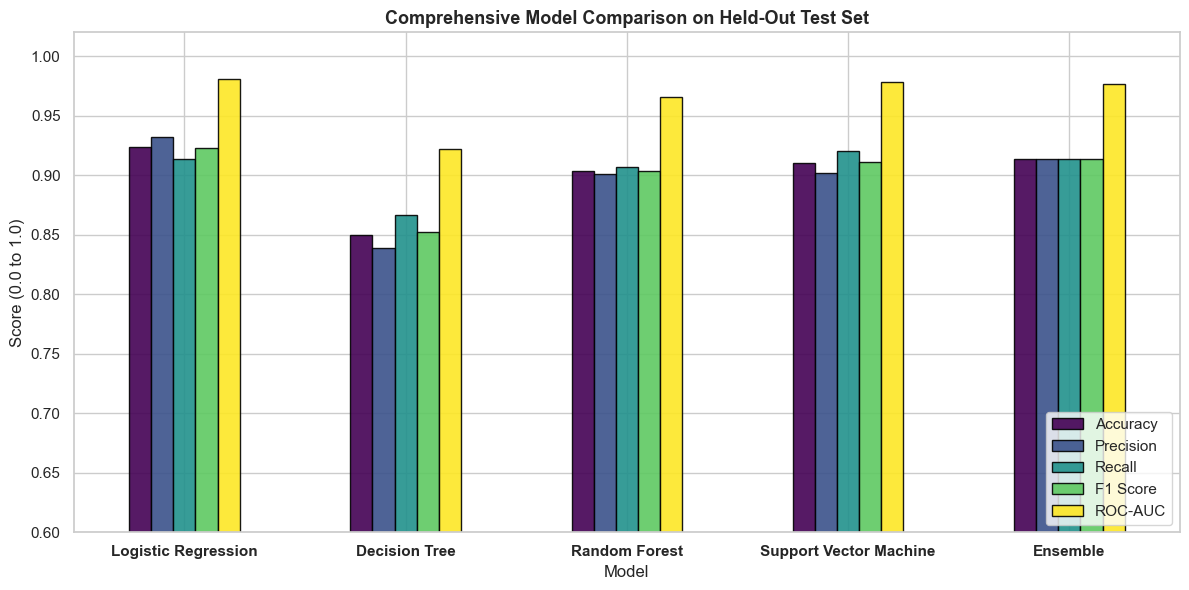

In [12]:
ax = metrics_df.plot(kind="bar", figsize=(12, 6), colormap="viridis", edgecolor="black", alpha=0.9)
plt.title("Comprehensive Model Comparison on Held-Out Test Set", weight="bold", fontsize=13)
plt.ylabel("Score (0.0 to 1.0)")
plt.ylim(0.6, 1.02)
plt.xticks(rotation=0, weight="bold")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

### Step 13: Receiver Operating Characteristic (ROC) Curves

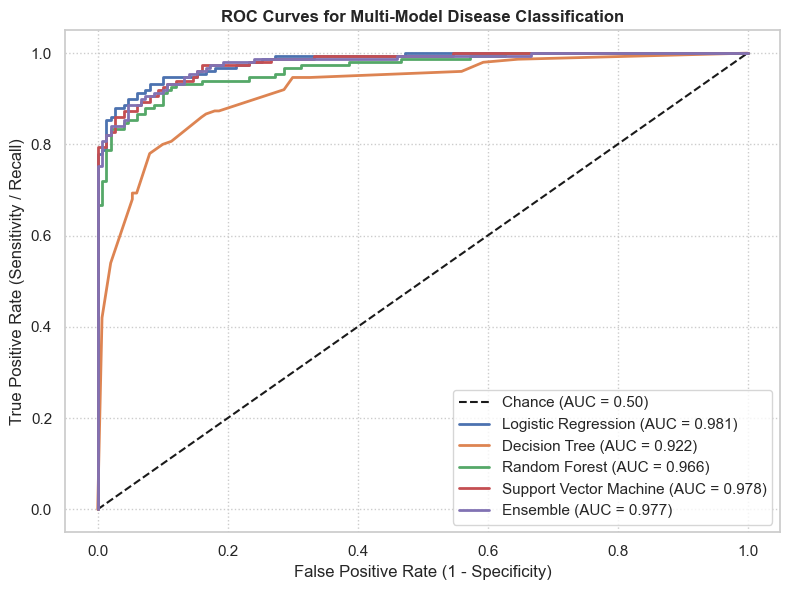

In [13]:
plt.figure(figsize=(8, 6))
plt.plot([0, 1], [0, 1], "k--", label="Chance (AUC = 0.50)")

for name, model in models.items():
    y_prob = model.predict_proba(X_test_trans)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc = roc_auc_score(y_test, y_prob)
    plt.plot(fpr, tpr, lw=2, label=f"{name} (AUC = {auc:.3f})")

plt.xlabel("False Positive Rate (1 - Specificity)")
plt.ylabel("True Positive Rate (Sensitivity / Recall)")
plt.title("ROC Curves for Multi-Model Disease Classification", weight="bold")
plt.legend(loc="lower right")
plt.grid(True, linestyle=":")
plt.tight_layout()
plt.show()

### Step 14: Confusion Matrices Across All Models

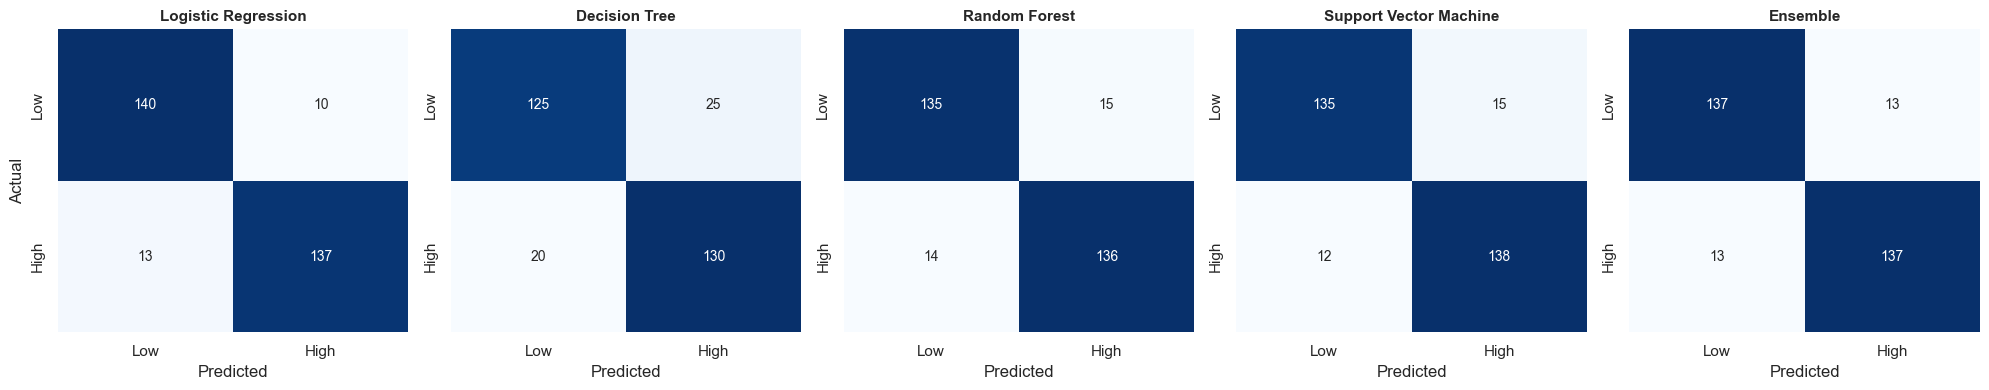

In [14]:
fig, axes = plt.subplots(1, 5, figsize=(20, 4))

for i, (name, model) in enumerate(models.items()):
    y_pred = model.predict(X_test_trans)
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[i],
                xticklabels=["Low", "High"], yticklabels=["Low", "High"])
    axes[i].set_title(name, weight="bold", fontsize=11)
    axes[i].set_xlabel("Predicted")
    if i == 0:
        axes[i].set_ylabel("Actual")

plt.tight_layout()
plt.show()

### Step 15: Feature Importance Ranking (Random Forest)

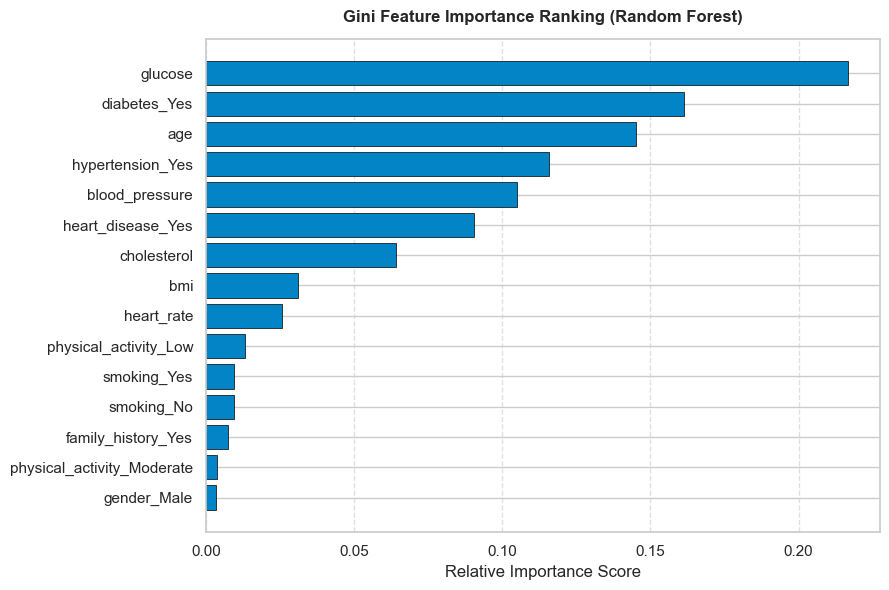

=== Top 5 Contributing Biomarkers ===
  glucose                  : 0.2167
  diabetes_Yes             : 0.1614
  age                      : 0.1451
  hypertension_Yes         : 0.1159
  blood_pressure           : 0.1050


In [15]:
# Extract one-hot encoded and scaled feature names
cat_encoder = preprocessor.named_transformers_["cat"].named_steps["encoder"]
encoded_cat_names = list(cat_encoder.get_feature_names_out(cat_features))
all_transformed_feature_names = num_features + encoded_cat_names

# Extract Gini importances from Random Forest
rf_importances = models["Random Forest"].feature_importances_
feat_df = pd.DataFrame({
    "Feature": all_transformed_feature_names,
    "Importance": rf_importances
}).sort_values(by="Importance", ascending=True)

plt.figure(figsize=(9, 6))
plt.barh(feat_df["Feature"], feat_df["Importance"], color="#0284c7", edgecolor="black", linewidth=0.5)
plt.title("Gini Feature Importance Ranking (Random Forest)", weight="bold", pad=12)
plt.xlabel("Relative Importance Score")
plt.grid(axis="x", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

print("=== Top 5 Contributing Biomarkers ===")
for _, row in feat_df.tail(5).iloc[::-1].iterrows():
    print(f"  {row['Feature']:<25}: {row['Importance']:.4f}")